<h3/>
<h1 align="center">Universidad de Buenos Aires (FIUBA)</h1>
<h2 align="center">Especialización en Inteligencia Artificial - CEIA - FIUBA</h2>
<h2 align="center">Procesamiento del Lenguaje Natural I</h2>
<h3 align="center">Desafío 2 - Custom embeddings con Gensim</h3>

<p align="left">
Alumno:
  <ul>
    <li>Nicolás Lastra</li>
  </ul>
</p>

# Planteo del problema y fuente de datos

Se entrenan embeddings de palabras propios con **Word2Vec** (Gensim) sobre un corpus en español: **_Don Quijote de la Mancha_** (Miguel de Cervantes), en la versión de texto plano de [Project Gutenberg](https://www.gutenberg.org/ebooks/2000). Los vectores resultantes reflejan cómo se usan las palabras en ese texto en particular.

> **Cada experimento debe estar acompañado de una explicación o interpretación de lo observado**, incluido el sustento de las decisiones tomadas (por ejemplo, cambios de hiperparámetros). La notebook tiene que poder correrse de inicio a fin sin errores.

## Consigna

1. **Embeddings propios.** Crear vectores con Gensim a partir de un corpus propio.
2. **Términos similares.** Elegir términos de interés y buscar los más y los menos similares.
3. **Reducción de dimensionalidad.** Llevar los embeddings a 2 dimensiones y graficarlos, eligiendo `MAX_WORDS` de forma que la visualización sea legible.
4. **Grupos de palabras.** Inspeccionar el gráfico, buscar pequeños grupos de palabras, interpretarlos y sacar conclusiones, acompañados con capturas.

---
## 0. Librerías y datos

In [1]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from nltk.tokenize import sent_tokenize
from nltk.corpus import stopwords
from gensim.models.callbacks import CallbackAny2Vec
from gensim.models import Word2Vec
from collections import Counter
from sklearn.manifold import TSNE

# Recursos de NLTK
nltk.download("punkt_tab", quiet=True)   # Modelo que detecta dónde termina cada oración
nltk.download("stopwords", quiet=True)   # Listas de stopwords por idioma

# Stopwords en español, se usan solo para filtrar el gráfico del punto 3, el modelo las conserva
stop_es = set(stopwords.words("spanish"))

# Definimos semilla para reproducibilidad
SEED = 42


In [2]:
ruta = Path("../docs/data/quijote.txt")

# El corpus está versionado en docs/data/. Se descargó de Project Gutenberg con:
# import urllib.request
# URL = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
# urllib.request.urlretrieve(URL, ruta)

if not ruta.exists():
    raise FileNotFoundError(f"No se encontró {ruta}. Descargarlo con las líneas comentadas de arriba.")

# Leemos documento
texto = ruta.read_text(encoding="utf-8")

# Se recorta encabezado y licencia de Gutenberg
inicio = texto.find("*** START OF")
fin = texto.find("*** END OF")
texto = texto[texto.find("\n", inicio) + 1 : fin]
print(f"{len(texto):,} caracteres")


2,110,713 caracteres


---
## 1. Preprocesamiento y entrenamiento de Word2Vec

In [3]:
# Preprocesamiento: separar en oraciones y tokenizar

# Tokenizador propio, pasa a minúsculas deja solo palabras (incluye tildes, ü y ñ).
# Descarta puntuación, números y los guiones de diálogo.
def tokenizar(oracion):
    return re.findall(r"[a-záéíóúüñ]+", oracion.lower()) #Pasamos a minusculas cada oracion y luego tokenizamos con el patron elegido.

oraciones_texto = sent_tokenize(texto, language="spanish") # Utilizamos el tokenizador de NLTK declarando el idioma, extraemos oraciones.
oraciones = [tokenizar(o) for o in oraciones_texto] # Aplicamos tokenizador con el patron propio, tokenizamos cada oración.
oraciones = [o for o in oraciones if len(o) >= 3]   # Descartamos oraciones de 1 o 2 palabras

n_tokens = sum(len(o) for o in oraciones)
print(f"Oraciones: {len(oraciones):,}")
print(f"Tokens:    {n_tokens:,}")
print(oraciones[0])
print(oraciones[1])
print(oraciones[2])

Oraciones: 9,260
Tokens:    383,089
['el', 'ingenioso', 'hidalgo', 'don', 'quijote', 'de', 'la', 'mancha', 'por', 'miguel', 'de', 'cervantes', 'saavedra', 'el', 'ingenioso', 'hidalgo', 'don', 'quijote', 'de', 'la', 'mancha', 'tasa', 'testimonio', 'de', 'las', 'erratas', 'el', 'rey', 'al', 'duque', 'de', 'béjar', 'prólogo', 'al', 'libro', 'de', 'don', 'quijote', 'de', 'la', 'mancha', 'que', 'trata', 'de', 'la', 'condición', 'y', 'ejercicio', 'del', 'famoso', 'hidalgo', 'don', 'quijote', 'de', 'la', 'mancha', 'que', 'trata', 'de', 'la', 'primera', 'salida', 'que', 'de', 'su', 'tierra', 'hizo', 'el', 'ingenioso', 'don', 'quijote', 'donde', 'se', 'cuenta', 'la', 'graciosa', 'manera', 'que', 'tuvo', 'don', 'quijote', 'en', 'armarse', 'caballero', 'de', 'lo', 'que', 'le', 'sucedió', 'a', 'nuestro', 'caballero', 'cuando', 'salió', 'de', 'la', 'venta', 'donde', 'se', 'prosigue', 'la', 'narración', 'de', 'la', 'desgracia', 'de', 'nuestro', 'caballero', 'del', 'donoso', 'y', 'grande', 'escrutini

In [4]:
# Análisis de la distribución de frecuencias del corpus
#
# Se cuentan dos cosas a distinguir:
#   - PALABRAS DISTINTAS: cada palabra cuenta una vez, sin importar cuántas veces aparezca
#   - TOKENS: cada aparición en el texto cuenta, independientemente de si se repite o no.

# Cantidad de apariciones de cada palabra. Las claves son las palabras distintas, los valores sus apariciones.
frecuencias = Counter(palabra for oracion in oraciones for palabra in oracion)

# TOKENS: total de apariciones de palabras en el corpus, con repeticiones
total_tokens = sum(frecuencias.values())

# TOKENS: apariciones de las palabras con 5 o más repeticiones (las que entran al vocabulario con min_count=5)
cubiertos = sum(f for f in frecuencias.values() if f >= 5)

# PALABRAS DISTINTAS: cada palabra que cumple suma 1
vocabulario = sum(f >= 5 for f in frecuencias.values())
aparecen_una_vez = sum(f == 1 for f in frecuencias.values())
aparecen_menos_de_5 = sum(f < 5 for f in frecuencias.values())

print("Tokens")
print(f"  Total en el corpus:                           {total_tokens:,}")
print(f"  Cubiertos por el vocabulario (min_count>=5):  {cubiertos:,} ({cubiertos / total_tokens:.1%})")
print()
print("Palabras distintas")
print(f"  Total en el corpus:                           {len(frecuencias):,}")
print(f"  Aparecen una sola vez:                        {aparecen_una_vez:,}")
print(f"  Aparecen menos de 5 veces (se descartan):     {aparecen_menos_de_5:,}")
print(f"  Vocabulario con min_count=5:                  {vocabulario:,}")

Tokens
  Total en el corpus:                           383,089
  Cubiertos por el vocabulario (min_count>=5):  355,114 (92.7%)

Palabras distintas
  Total en el corpus:                           22,870
  Aparecen una sola vez:                        11,138
  Aparecen menos de 5 veces (se descartan):     17,552
  Vocabulario con min_count=5:                  5,318


In [5]:
# Utilizamos la clase base de CallbackAny2Vec para informar el loss por época.    
# Gensim acumula el loss en un float32 que pierde precisión cuando el valor crece
# (mostraba una caída falsa desde la época 25). Se resetea al final de cada época
# para obtener el loss de esa época sola.

class callback(CallbackAny2Vec):
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        print(f"Época {self.epoch:2d} - loss: {loss:,.0f}")
        model.running_training_loss = 0.0   # Reset del acumulado interno de Gensim
        self.epoch += 1

In [6]:
# Modelo Word2Vec: vocabulario y entrenamiento

modelo_sg = Word2Vec(
    vector_size=100,   # Dimension de cada embedding.
    window=5,          # Ventana de contexto, 5 palabras a cada lado, las oraciones del Quijote son largas.
    min_count=5,       # Palabras con menos de 5 apariciones quedan fuera del vocabulario ya que no tienen contexto suficiente.
    sg=1,              # Utiliza skip-gram, mejor que CBOW para corpus chicos y palabras poco frecuentes.
    negative=10,       # Por cada par real se comparan 10 palabras al azar como ejemplos negativos.
    workers=1,         # Utiliza un solo hilo de la CPU para que el resultado sea reproducible.
    seed=SEED,         # Semilla, junto con workers fijan la reproducibilidad.
)

modelo_sg.build_vocab(oraciones)
print(f"Palabras distintas en el vocabulario (min_count=5): {len(modelo_sg.wv):,}")

Palabras distintas en el vocabulario (min_count=5): 5,318


In [7]:
# Entrenamiento: 30 pasadas completas por el corpus, imprimiendo el loss de cada época
modelo_sg.train(
    oraciones,
    total_examples=modelo_sg.corpus_count,   # cantidad de oraciones, la calculó con build_vocab
    epochs=30,                                 # pasadas completas por el corpus
    compute_loss=True,                         # necesario para que el callback tenga un loss para mostrar
    callbacks=[callback()],
)

Época  0 - loss: 4,215,029
Época  1 - loss: 3,837,931
Época  2 - loss: 3,785,520
Época  3 - loss: 3,757,006
Época  4 - loss: 3,722,410
Época  5 - loss: 3,687,572
Época  6 - loss: 3,673,818
Época  7 - loss: 3,652,191
Época  8 - loss: 3,637,644
Época  9 - loss: 3,621,591
Época 10 - loss: 3,604,104
Época 11 - loss: 3,598,559
Época 12 - loss: 3,596,131
Época 13 - loss: 3,589,518
Época 14 - loss: 3,575,555
Época 15 - loss: 3,570,028
Época 16 - loss: 3,556,740
Época 17 - loss: 3,565,764
Época 18 - loss: 3,552,385
Época 19 - loss: 3,544,636
Época 20 - loss: 3,541,577
Época 21 - loss: 3,555,216
Época 22 - loss: 3,545,584
Época 23 - loss: 3,543,840
Época 24 - loss: 3,546,727
Época 25 - loss: 3,557,315
Época 26 - loss: 3,537,146
Época 27 - loss: 3,542,880
Época 28 - loss: 3,554,466
Época 29 - loss: 3,552,744


(7164920, 11492670)

In [8]:
#Realizamos el mismo seteo pero utilizando la arquitectura CBOW
modelo_cbow = Word2Vec(
    vector_size=100, 
    window=5, 
    min_count=5,
    sg=0,          
    negative=10,
    workers=1,
    seed=SEED,
)

modelo_cbow.build_vocab(oraciones)
print(f"Palabras distintas en el vocabulario (min_count=5): {len(modelo_cbow.wv):,}")

Palabras distintas en el vocabulario (min_count=5): 5,318


In [9]:
# Entrenamiento: 30 pasadas completas por el corpus, imprimiendo el loss de cada época
modelo_cbow.train(
    oraciones,
    total_examples=modelo_cbow.corpus_count,
    epochs=30,
    compute_loss=True,
    callbacks=[callback()],
)

Época  0 - loss: 934,561
Época  1 - loss: 797,514
Época  2 - loss: 757,027
Época  3 - loss: 727,018
Época  4 - loss: 703,400
Época  5 - loss: 685,859
Época  6 - loss: 672,878
Época  7 - loss: 660,064
Época  8 - loss: 648,365
Época  9 - loss: 639,606
Época 10 - loss: 629,192
Época 11 - loss: 622,864
Época 12 - loss: 615,456
Época 13 - loss: 609,376
Época 14 - loss: 603,040
Época 15 - loss: 596,510
Época 16 - loss: 590,545
Época 17 - loss: 586,772
Época 18 - loss: 581,149
Época 19 - loss: 576,702
Época 20 - loss: 573,516
Época 21 - loss: 572,325
Época 22 - loss: 566,865
Época 23 - loss: 564,946
Época 24 - loss: 561,735
Época 25 - loss: 558,841
Época 26 - loss: 555,845
Época 27 - loss: 554,307
Época 28 - loss: 553,836
Época 29 - loss: 552,062


(7164920, 11492670)

**Análisis:**

**Corpus.** Se usó *Don Quijote de la Mancha* en la versión de texto plano de Project Gutenberg, sin el encabezado ni la licencia en inglés del archivo original (quedan 2.110.713 caracteres). Recortarlos evita que el modelo aprenda vocabulario ajeno al libro ("license", "copyright", "foundation").

**Preprocesamiento.** Se hizo en dos niveles:

1. **Oraciones**, con `sent_tokenize` de NLTK (modelo Punkt para español), que distingue los puntos finales de los de abreviaturas. Word2Vec necesita el texto separado en oraciones porque la ventana de contexto se mueve dentro de cada una, y así no relaciona la última palabra de una oración con la primera de la siguiente.
2. **Palabras**, con un tokenizador propio basado en una expresión regular (`[a-záéíóúüñ]+`) aplicada sobre el texto en minúsculas. Se eligió en lugar de `word_tokenize`, que deja los signos `¿` y `¡` pegados a la palabra (`'¿Qué'`): con el filtro `isalpha()` del Desafío 1, esas palabras se habrían descartado enteras.

Se descartaron las oraciones de menos de 3 palabras (títulos sueltos y réplicas cortas de diálogo). Quedaron **9.260 oraciones y 383.089 tokens**.

Las decisiones de preprocesamiento son distintas a las del Desafío 1, porque cambia lo que se hace después:

| Decisión | Desafío 1 (TF-IDF) | Desafío 2 (Word2Vec) | Motivo |
|---|---|---|---|
| Stopwords | Se eliminaron | **Se mantuvieron** | Word2Vec aprende del contexto, eliminarlas cambiaría las vecinas de cada palabra dentro de la ventana |
| Lematización | Sí | **No** | Se prefiere que el modelo aprenda por sí mismo la relación entre variantes ("dinero" y "dineros" quedan entre sus vecinos mutuos) |
| Tildes | — | **Se mantuvieron** | En español distinguen palabras distintas: *el/él* (8.267 / 1.282 apariciones), *si/sí* (1.968 / 346), *mas/más* (240 / 2.055; Cervantes usa "mas" como "pero") |

**Limitación observada.** `sent_tokenize` solo corta en `.`, `?` y `!`, y Cervantes encadena frases con `;` y `:`, por lo que hay "oraciones" de cientos de palabras (la más larga tiene 2.442). Además, la portada y el índice del libro quedaron unidos en la primera oración, porque esas líneas no tienen punto. No afecta demasiado al entrenamiento, porque la ventana de contexto limita igual cuántas palabras se relacionan entre sí.

**Vocabulario.**

| | Palabras distintas | Tokens |
|---|---|---|
| Total en el corpus | 22.870 | 383.089 |
| Aparecen una sola vez | 11.138 (49 %) | — |
| Descartadas (menos de 5 apariciones) | 17.552 (77 %) | 27.975 (7,3 %) |
| **Vocabulario con `min_count=5`** | **5.318 (23 %)** | **355.114 (92,7 %)** |

Con `min_count=5` el vocabulario se reduce a menos de un cuarto, pero conserva el **92,7 % del texto**. Las palabras descartadas aparecen tan pocas veces que el modelo no tendría contextos suficientes para aprender un vector confiable, casi la mitad del vocabulario aparece una sola vez.

**Hiperparámetros.**

| Parámetro | Valor | Justificación |
|---|---|---|
| `vector_size` | 100 | Con ~380 mil tokens no hay datos suficientes para aprender bien 300 dimensiones |
| `window` | 5 | Una ventana amplia captura relaciones de tema (personajes, escenas) más que de función gramatical |
| `min_count` | 5 | Ver tabla de vocabulario |
| `sg` | 1 (skip-gram) | Funciona mejor que CBOW en corpus chicos y con palabras poco frecuentes (se valida en el punto 2) |
| `negative` | 10 | Valor recomendado para corpus chicos (entre 5 y 20) |
| `workers` y `seed` | 1 y 42 | Con un solo hilo y semilla fija, el entrenamiento es reproducible |

**Entrenamiento.** En la primera corrida, el loss mostró una caída de 2,5 millones a ~118 mil en la época 25. No era una mejora real, Gensim acumula el loss en un `float32`, que pierde precisión cuando el acumulado supera las decenas de millones, y las restas entre épocas daban valores falsos. Se corrigió reseteando el acumulado al final de cada época en el callback.

Con la corrección, el loss de skip-gram baja de 4.215.029 a 3.837.931 en la primera época (−9 %), sigue bajando lentamente hasta la época 15 (~3,57 millones) y luego oscila en torno a 3,55 millones con variaciones menores al 0,5 %. El modelo convergió, y **30 épocas son suficientes**.

**Skip-gram frente a CBOW.** Se entrenó un segundo modelo con los mismos hiperparámetros y `sg=0`. CBOW termina con un loss de ~552 mil, contra ~3,55 millones de skip-gram, y es unas 4 veces más rápido. **Esos valores no son comparables**, el loss es una suma sobre los ejemplos de la época, y CBOW hace una predicción por palabra central, mientras que skip-gram hace una por cada par (central, contexto), unas 6 veces más ejemplos. Lo comparable es la forma de las curvas, ambas bajan y se estabilizan. La calidad de cada modelo se compara a partir de los términos similares en el punto 2 de esta notebook.

---
## 2. Términos más y menos similares

In [10]:
# Términos de interés elegidos a mano

terminos = ["molinos", "yelmo", "dulcinea", "cura", "ínsula", "lanza", "libros", "loco"]

# Verificamos que todos estén en el vocabulario (min_count=5) y cuántas veces aparecen
for t in terminos:
    estado = "Esta en el vocabulario" if t in modelo_sg.wv else "No está en el vocabulario"
    print(f"{t:10s} {frecuencias[t]:5d} apariciones  {estado}")


molinos       13 apariciones  Esta en el vocabulario
yelmo         40 apariciones  Esta en el vocabulario
dulcinea     286 apariciones  Esta en el vocabulario
cura         317 apariciones  Esta en el vocabulario
ínsula       119 apariciones  Esta en el vocabulario
lanza         64 apariciones  Esta en el vocabulario
libros       148 apariciones  Esta en el vocabulario
loco         111 apariciones  Esta en el vocabulario


In [11]:
# Más similares con skip-gram (most_similar positive)

TOPN = 8 # Se analizan el top 8.

mas_similares_sg = pd.DataFrame({
    t: [f"{palabra} ({similitud:.2f})" for palabra, similitud in modelo_sg.wv.most_similar(positive=[t], topn=TOPN)]
    for t in terminos
})
mas_similares_sg

,molinos,yelmo,dulcinea,cura,ínsula,lanza,libros,loco
0,imaginada (0.69),mambrino (0.83),toboso (0.87),barbero (0.71),barataria (0.69),adarga (0.73),caballerías (0.74),cuerdo (0.69)
1,viento (0.65),bacía (0.67),señora (0.64),canónigo (0.60),posesión (0.58),arrimado (0.64),mentirosos (0.59),tema (0.56)
2,gigantes (0.61),sucedidas (0.56),única (0.61),bachiller (0.60),gobernar (0.58),embrazó (0.63),impresos (0.55),decirlo (0.53)
3,vestiglos (0.61),inferir (0.53),aldonza (0.60),nicolás (0.57),gobierno (0.57),escudo (0.60),imprimir (0.53),reinaldos (0.52)
4,ejércitos (0.59),jaez (0.53),desencantada (0.57),escrutinio (0.55),conde (0.56),arrimada (0.60),disparatados (0.52),tonto (0.50)
5,aparato (0.57),albarda (0.53),llamarla (0.56),carrasco (0.55),gobernador (0.53),embrazando (0.58),autores (0.52),menguado (0.50)
6,tortas (0.56),morrión (0.50),transformada (0.55),licenciado (0.55),prometida (0.53),brinco (0.56),componen (0.51),intérprete (0.50)
7,recordación (0.55),simplicidades (0.49),desencantar (0.54),ventero (0.54),condado (0.50),estribos (0.56),letura (0.51),desgraciado (0.49)


In [12]:
# Más similares con CBOW (most_similar positive)

TOPN = 8 # Se analizan el top 8.

mas_similares_cbow = pd.DataFrame({
    t: [f"{palabra} ({similitud:.2f})" for palabra, similitud in modelo_cbow.wv.most_similar(positive=[t], topn=TOPN)]
    for t in terminos
})
mas_similares_cbow

,molinos,yelmo,dulcinea,cura,ínsula,lanza,libros,loco
0,gigantes (0.65),mambrino (0.74),toboso (0.52),canónigo (0.66),cédula (0.56),adarga (0.76),caballerías (0.68),cuerdo (0.68)
1,pastores (0.61),pintor (0.56),vandalia (0.52),ventero (0.63),posesión (0.54),espada (0.71),versos (0.58),mentecato (0.55)
2,géneros (0.60),albarda (0.55),princesa (0.48),licenciado (0.61),hazaña (0.51),silla (0.71),poetas (0.57),viejo (0.55)
3,acaecimientos (0.60),soneto (0.55),micomicona (0.47),duque (0.60),casa (0.51),almohada (0.68),autores (0.54),tonto (0.52)
4,comedimientos (0.59),bacía (0.52),angélica (0.46),barbero (0.59),empresa (0.50),mula (0.68),gobernadores (0.54),gracioso (0.50)
5,religiosos (0.59),pierres (0.51),belerma (0.45),cabrero (0.57),noche (0.49),furia (0.66),impresos (0.53),bueno (0.50)
6,siguen (0.59),barbero (0.49),par (0.45),virrey (0.56),promesa (0.49),cabeza (0.66),disparates (0.53),ladrón (0.48)
7,prados (0.59),jaez (0.49),linda (0.43),mayordomo (0.55),diciplina (0.49),rodela (0.66),componen (0.52),cansado (0.47)


In [13]:
# Menos similares con skip-gram (most_similar negative)

menos_similares_sg = pd.DataFrame({
    t: [f"{palabra} ({similitud:.2f})" for palabra, similitud in modelo_sg.wv.most_similar(negative=[t], topn=TOPN)]
    for t in terminos
})
menos_similares_sg

,molinos,yelmo,dulcinea,cura,ínsula,lanza,libros,loco
0,teniendo (0.08),mortales (0.11),hicieron (0.07),heridas (0.13),sentía (0.10),allá (0.13),rendido (0.12),ruidera (0.12)
1,alcalde (0.08),queriendo (0.11),algo (0.06),diamante (0.11),encomendándose (0.10),tenemos (0.13),yegua (0.12),sirven (0.10)
2,verás (0.07),visitar (0.11),coge (0.06),veen (0.10),vienen (0.09),carrasco (0.10),asida (0.11),quiteria (0.09)
3,tenía (0.07),ojos (0.10),arma (0.06),miserable (0.09),presencia (0.07),darte (0.10),harto (0.11),tendrían (0.09)
4,determinado (0.07),amos (0.09),partió (0.05),caen (0.07),ademán (0.07),principalmente (0.09),tendido (0.11),flor (0.09)
5,vecino (0.06),suspiros (0.08),puntas (0.05),tesoros (0.07),caso (0.07),particular (0.09),viuda (0.10),mostraron (0.08)
6,segundo (0.06),sentimientos (0.08),año (0.05),entera (0.06),ante (0.06),sesenta (0.09),recebir (0.09),quietud (0.08)
7,cecial (0.06),ofreció (0.07),vaca (0.05),apartarse (0.06),levantando (0.05),gobiernos (0.08),ves (0.09),cerdas (0.08)


In [14]:
# Menos similares con CBOW (most_similar negative)

menos_similares_cbow = pd.DataFrame({
    t: [f"{palabra} ({similitud:.2f})" for palabra, similitud in modelo_cbow.wv.most_similar(negative=[t], topn=TOPN)]
    for t in terminos
})
menos_similares_cbow

,molinos,yelmo,dulcinea,cura,ínsula,lanza,libros,loco
0,fui (0.44),amos (0.46),hicieron (0.33),bestia (0.37),tanta (0.43),desto (0.45),verás (0.45),vuelvan (0.46)
1,tomé (0.43),hayan (0.43),recio (0.32),so (0.35),levantando (0.39),decirte (0.42),detuvo (0.43),presos (0.45)
2,esposo (0.42),parientes (0.42),comieron (0.32),cárcel (0.34),molineros (0.39),deciros (0.39),tuya (0.43),hermandad (0.45)
3,hice (0.41),padres (0.40),antojos (0.31),armado (0.34),herido (0.38),dudo (0.36),tendido (0.41),fuentes (0.43)
4,esposa (0.40),medios (0.39),tomó (0.30),abra (0.34),claudia (0.36),ten (0.36),asno (0.40),verdugos (0.42)
5,marido (0.39),hijas (0.39),estados (0.30),engendró (0.33),demás (0.35),negar (0.36),pobre (0.40),nata (0.41)
6,cecial (0.39),buscarle (0.39),hábitos (0.29),católica (0.33),necesarios (0.35),seáis (0.36),asida (0.39),piden (0.41)
7,deseo (0.38),den (0.38),alforjas (0.29),bronce (0.32),escribía (0.35),acabo (0.36),yegua (0.39),corren (0.41)


**Análisis:**

**Elección de términos.** Se eligieron 8 términos de categorías distintas, para ver qué tipo de relación captura el modelo en cada caso: episodios (*molinos*, *yelmo*), personajes (*dulcinea*, *cura*), lugares (*ínsula*), objetos (*lanza*), el tema de fondo de la novela (*libros*) y un adjetivo (*loco*). Todos están en el vocabulario, con frecuencias desde 13 (*molinos*) hasta 317 apariciones (*cura*), lo que permite ver también cómo se comporta cada modelo con palabras poco frecuentes.

**Más similares con skip-gram.** Todos los términos dan vecinos coherentes con la novela, con similitudes entre 0,49 y 0,87. El tipo de relación cambia según el término:

| Tipo de relación | Ejemplos |
|---|---|
| Fantasía y realidad de un mismo episodio | *molinos* → imaginada, viento, gigantes, vestiglos · *yelmo* → bacía (el "yelmo" es una bacía de barbero) |
| Frases fijas y nombres compuestos | *dulcinea* → toboso (0,87) |
| Personajes que comparten escenas | *cura* → barbero, bachiller, nicolás, carrasco, escrutinio |
| Campo semántico | *ínsula* → barataria, gobernar, gobierno, gobernador |
| Expresiones de la época | *lanza* → adarga, embrazó, escudo |
| Juicio del narrador | *libros* → caballerías, mentirosos, disparatados |
| Antónimos | *loco* → cuerdo |

Las similitudes más altas corresponden a frases fijas, "Dulcinea" casi siempre va seguida de "del Toboso", y "yelmo" de "de Mambrino". Con contextos tan repetidos, los vectores quedan muy próximos.

El caso de *loco → cuerdo* muestra que Word2Vec (tanto sg como cbow), **mide similitud de uso, no de significado**. Los antónimos aparecen en los mismos contextos ("más loco que cuerdo"), por lo que el modelo los ubica cerca.

El modelo conserva la ortografía de la época (*letura*, *recebir*, *veen*), que un modelo pre-entrenado en español moderno no tendría.

**Skip-gram frente a CBOW.** Los dos modelos capturan relaciones de distinto tipo.

- **Skip-gram agrupa por asociación temática**, es decir, qué aparece junto en la historia: *cura* → los personajes con los que comparte escenas; *ínsula* → Barataria y el gobierno de Sancho; *dulcinea* → su nombre real, Aldonza.
- **CBOW agrupa por tipo o rol de la palabra**, es decir, qué puede ocupar el mismo lugar en la oración: *cura* → cargos y oficios (ventero, licenciado, duque, cabrero, virrey, mayordomo); *loco* → adjetivos para personas (mentecato, viejo, gracioso, ladrón); *lanza* → objetos (espada, silla, almohada, mula); *dulcinea* → otras damas de los libros de caballería (Angélica, Belerma, la princesa Micomicona).

La diferencia viene de cómo entrena cada uno, CBOW promedia el contexto para predecir la palabra central, así que aprende qué palabras son intercambiables en un mismo hueco. Skip-gram aprende de cada par (palabra, vecina) por separado y captura con qué palabras concretas aparece cada una.

Skip-gram es claramente mejor en dos casos:
- **Palabras poco frecuentes:** *molinos* (13 apariciones) da en CBOW *pastores, géneros, acaecimientos, comedimientos*, casi ruido, frente a *imaginada, viento, gigantes* en skip-gram.
- ***ínsula*:** CBOW no encuentra Barataria y devuelve palabras genéricas (*casa, noche, empresa*).

**Menos similares.** Con skip-gram, todas las similitudes están entre 0,05 y 0,13 prácticamente 0. Las palabras no tienen relación con el término (*molinos* → teniendo, alcalde, verás, tenía). Esto muestra que **en Word2Vec no hay "opuestos"**, lo menos similar es lo que nunca comparte contexto, un vector casi perpendicular, y no uno que apunte en sentido contrario. Los opuestos semánticos, como se vio con *loco* y *cuerdo*, quedan cerca.

Con CBOW, en cambio, las menos similares tienen similitudes de **0,29 a 0,46**, hasta las palabras menos relacionadas son bastante parecidas entre sí. Los vectores de CBOW ocupan una región más estrecha del espacio, y la escala de similitudes queda comprimida.

| Modelo | Más similares | Menos similares |
|---|---|---|
| Skip-gram | 0,49 – 0,87 | 0,05 – 0,13 |
| CBOW | 0,43 – 0,76 | 0,29 – 0,46 |

Skip-gram separa mucho mejor lo relacionado de lo no relacionado.

**Conclusión.** Se elige **skip-gram** para los puntos 3 y 4 ya que captura mejor las relaciones propias de la novela (personajes, episodios, lugares), que es lo que interesa visualizar, es más robusto con palabras poco frecuentes y discrimina mejor entre palabras relacionadas y no relacionadas. CBOW no es peor en todo, porque agrupa mejor por función gramatica, pero para este corpus y este objetivo skip-gram es la mejor opción.

---
## 3. Reducción de dimensionalidad y visualización

In [15]:
# Reducción a 2 dimensiones, utilizamos el algoritmo t-SNE (t-distributed Stochastic Neighbor Embedding) 
# para reducir la dimension de los embedding y poder visualizarlos.

tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
vectores_2d = tsne.fit_transform(modelo_sg.wv.vectors)

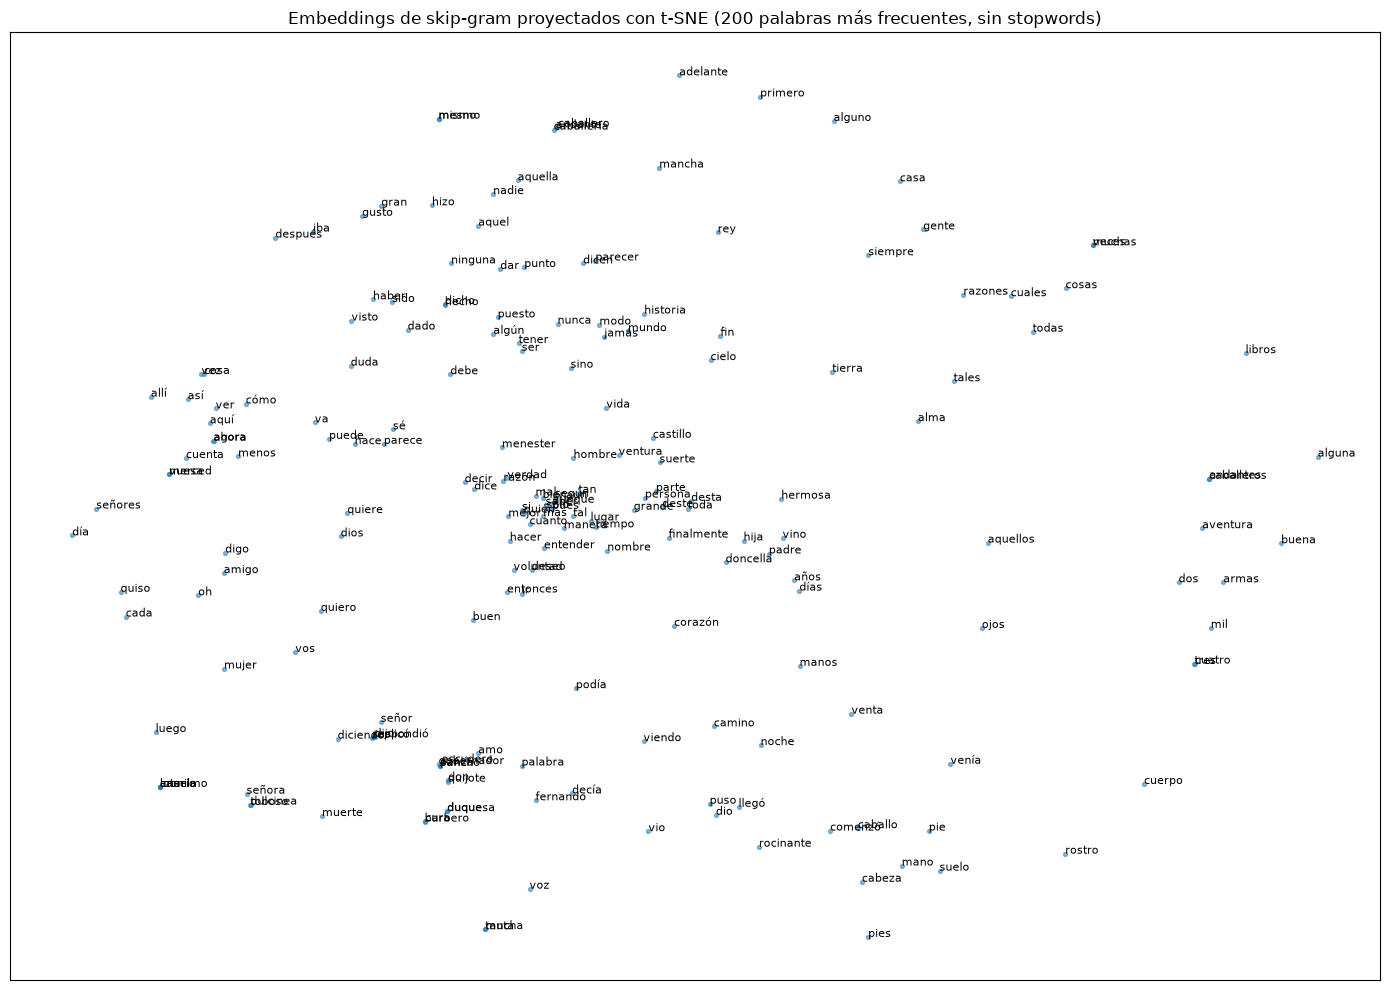

In [16]:
MAX_WORDS = 200 #Cantidad maxima de palabras que se van a representar en el grafico/imagen.

# index_to_key está ordenado por frecuencia, se toman las MAX_WORDS más frecuentes
# que no son stopwords (el modelo las usó para entrenar, pero no aportan en este grafico por eso se las saca)
indices = [i for i, palabra in enumerate(modelo_sg.wv.index_to_key) if palabra not in stop_es][:MAX_WORDS]

# Definimos el tamaño de la figura y graficamos
fig, ax = plt.subplots(figsize=(14, 10))
ax.scatter(vectores_2d[indices, 0], vectores_2d[indices, 1], s=8, alpha=0.5)

# Recorremos cada indice y agregamos la palabra que representa 
for i in indices:
    ax.annotate(modelo_sg.wv.index_to_key[i], (vectores_2d[i, 0], vectores_2d[i, 1]), fontsize=8)

ax.set_title(f"Embeddings de skip-gram proyectados con t-SNE ({MAX_WORDS} palabras más frecuentes, sin stopwords)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig("../docs/img/desafio2_tsne.png", dpi=120)   # Guarda la imagen dentro de docs.
plt.show()

**Análisis:**

**Reducción de dimensionalidad.** Se usó t-SNE para llevar los vectores de 100 a 2 dimensiones. A diferencia de PCA, que proyecta sobre las direcciones de mayor varianza global, t-SNE reacomoda los puntos intentando que cada palabra conserve a sus vecinas cercanas, lo que lo hace más adecuado para ver grupos. Se aplicó sobre todo el vocabulario (5.318 palabras), con `perplexity=30` (valor por defecto) y `random_state=SEED` para que el gráfico sea reproducible.

Al interpretarlo hay que tener en cuenta que t-SNE conserva las vecindades locales, pero no las distancias globales: lo que tiene significado es qué palabras quedan juntas, no la distancia entre grupos ni los valores de los ejes (por eso se ocultaron).

**Palabras graficadas.** `index_to_key` está ordenado por frecuencia, así que las primeras palabras son casi todas stopwords (*que, de, y, la…*). Para el gráfico se filtraron con la lista en español de NLTK, el modelo las conserva y las usó para entrenar, solo que no se dibujan.

**Elección de `MAX_WORDS`.** Se probaron varios valores:

| `MAX_WORDS` | Resultado |
|---|---|
| 100 | Legible, pero casi no se forman grupos |
| **200** | **Grupos claros y etiquetas legibles en la mayor parte del gráfico** |
| 300 | Aparecen algunos grupos nuevos, pero las etiquetas del centro se vuelven ilegibles |

Se eligió **200**, por debajo no hay palabras suficientes para que se formen grupos, y por encima la superposición crece más rápido que la información nueva.

**Observaciones.** Se distinguen grupos con sentido (partes del cuerpo, verbos de acción en pasado, protagonistas, verbos de diálogo, números), que se analizan en el punto 4. En el centro se amontonan palabras generales (*tan, decir, hacer, verdad, tal*), aparecen en contextos de todo tipo y t-SNE no logra asignarlas a ningún grupo. Este amontonamiento aparece con cualquier valor de `MAX_WORDS`.

---
## 4. Grupos de palabras

_Grupos identificados en el gráfico, con capturas en `docs/img/`:_

<!-- ![Grupo 1](../docs/img/desafio2_grupo1.png) -->

**Análisis:**

_Completar._

---
## Conclusiones

_Completar._